# B2B Client Score Stability: Cohort vs Old Approach

This notebook evaluates forward classification stability and same-period differences between approaches using separate input maps:

1. **Forward classification stability:** Do clients tagged in October 2025-January 2026 retain their classification in February-May 2026? Section 6 and its identification/decile follow-ups use only `CONFIG["forward_files"]`. February-May is a four-month comparison window, despite legacy internal labels containing "Next 3M".
2. **Same-period comparison:** The original base comparisons use `CONFIG["files"]`. Section 11 compares Cohort and Old classifications and shows funded amounts as both row percentages and percentages of total matched funding.

All analysis uses `rawTotal`, filters `MetricName == "Client"`, and matches clients on `MetricValue`. Each population is classified using its own portfolio Z and configurable threshold multipliers. Section 11 lists all severe Old-versus-Cohort disagreements for the original base population and both forward-test windows, with both approaches' volume, funding, and component scores.

## 1. Set Parameters and File Map

Change `score_column` only to switch score families. The default direction is resolved automatically from `score_band_directions`: TotalScore treats high scores as Favourable, while CPRScore and PRScore treat low scores as Favourable. Set `score_band_direction` explicitly only when overriding that default.

The reference workbook's `Client!U10` is `=+rawTotal!Y3`, the stored `TotalScore` on the portfolio row where `ProductCategory == "All"`, `MetricName == "Total"`, and `MetricValue == "Total"`. Its value is **0.550714**, not an average of client scores. Each input workbook supplies its own portfolio baseline **Z**, selected by these row labels rather than a fixed Excel address. When switching score families, Z comes from the selected score column on that same portfolio row.

`favourable_multiplier` (default **1.25**) and `unfavourable_multiplier` (default **0.75**) parameterize the upper and lower cutoffs. For TotalScore, Favourable means `score >= Z * 1.25`, Unfavourable means `score < Z * 0.75`, and Neutral includes the lower cutoff but excludes the upper cutoff. The reference cutoffs are **0.6883925** and **0.4130355**. Excel itself uses `<=` for Unfavourable; this notebook deliberately uses the requested strict `<` rule. Lower-is-favourable score families retain their reversed direction: Favourable at or below the lower cutoff, Unfavourable at or above the upper cutoff.

In [1]:
CONFIG = {
    "sheet_name": "rawTotal",
    "metric_name": "Client",
    "client_key": "MetricValue",
    "score_column": "TotalScore",
    "score_band_direction": None,
    "score_band_directions": {
        "TotalScore": "higher_is_favourable",
        "CPRScore": "lower_is_favourable",
        "PRScore": "lower_is_favourable",
    },
    "component_score_candidates": ["CPRScore", "RecapScore", "TotalScore"],
    "rank_column": "VolumeRank",
    "favourable_multiplier": 1.25,
    "unfavourable_multiplier": 0.75,
    "deciles": 10,
    "output_directory": "b2b_stability_outputs",
    "forward_periods": {
        "Base": "October 2025-January 2026",
        "Comparison": "February-May 2026",
    },
    "forward_files": {
        "Cohort Base": "stability_test/B2B_cohort_score_20260131_upd_Oct_Jan.xlsx",
        "Old Base": "stability_test/B2B_reporting_raw_20260531_Oct_Jan.xlsx",
        "Cohort Next 3M": "stability_test/B2B_cohort_score_20260531_upd_Feb_May.xlsx",
        "Old Next 3M": "stability_test/B2B_reporting_raw_20260531_Feb_May.xlsx",
    },
    "files": {
        "Cohort Base": "stability_test/B2B_cohort_score_20260531_upd.xlsx",
        "Old Base": "stability_test/B2B_reporting_raw_20260531.xlsx",
    },
}

resolved_direction = CONFIG["score_band_direction"] or CONFIG["score_band_directions"].get(
    CONFIG["score_column"]
)
assert 0 < CONFIG["unfavourable_multiplier"] < CONFIG["favourable_multiplier"] < float("inf"), (
    "Multipliers must be finite and positive, with the lower multiplier below the upper multiplier."
)
assert resolved_direction in {"higher_is_favourable", "lower_is_favourable"}, (
    "Provide a valid score_band_direction or add the score column to score_band_directions."
)
CONFIG

{'sheet_name': 'rawTotal',
 'metric_name': 'Client',
 'client_key': 'MetricValue',
 'score_column': 'TotalScore',
 'score_band_direction': None,
 'score_band_directions': {'TotalScore': 'higher_is_favourable',
  'CPRScore': 'lower_is_favourable',
  'PRScore': 'lower_is_favourable'},
 'component_score_candidates': ['CPRScore', 'RecapScore', 'TotalScore'],
 'rank_column': 'VolumeRank',
 'favourable_multiplier': 1.25,
 'unfavourable_multiplier': 0.75,
 'deciles': 10,
 'output_directory': 'b2b_stability_outputs',
 'forward_periods': {'Base': 'October 2025-January 2026',
  'Comparison': 'February-May 2026'},
 'forward_files': {'Cohort Base': 'stability_test/B2B_cohort_score_20260131_upd_Oct_Jan.xlsx',
  'Old Base': 'stability_test/B2B_reporting_raw_20260531_Oct_Jan.xlsx',
  'Cohort Next 3M': 'stability_test/B2B_cohort_score_20260531_upd_Feb_May.xlsx',
  'Old Next 3M': 'stability_test/B2B_reporting_raw_20260531_Feb_May.xlsx'},
 'files': {'Cohort Base': 'stability_test/B2B_cohort_score_202605

## 2. Import Libraries and Configure Display

In [2]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
COLORS = {"Cohort": "#176B87", "Old": "#C65D35"}
CLASS_ORDER = ["Favourable", "Neutral", "Unfavourable"]
ROOT = Path.cwd()
OUTPUT_DIR = ROOT / CONFIG["output_directory"]
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Working directory: {ROOT}")
print(f"Outputs: {OUTPUT_DIR}")

Working directory: e:\Development\Shashi\B2B-Pricing-Model\repo\python
Outputs: e:\Development\Shashi\B2B-Pricing-Model\repo\python\b2b_stability_outputs


## 3-5. Load, Standardize, Validate, and Tag Client Rows

Each workbook's portfolio Total row is validated before filtering to one row per client. That file's Z and parameterized cutoffs determine its client classifications; the threshold audit table below lists the values used for every dataset. Missing, duplicate, nonfinite, or nonpositive portfolio baselines are treated as errors. Client rows are expected to be unique; duplicates are treated as a data-quality error rather than silently discarded.

In [3]:
def derive_score_thresholds(frame, label, score_column=None):
    """Resolve Client!U10's portfolio Total-row baseline and scaled cutoffs."""
    score_column = score_column or CONFIG["score_column"]
    required = {"MetricName", "MetricValue", "ProductCategory", score_column}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{label}: missing baseline columns: {sorted(missing)}")
    totals = frame.loc[
        frame["MetricName"].eq("Total")
        & frame["MetricValue"].eq("Total")
        & frame["ProductCategory"].eq("All"),
        score_column,
    ]
    if len(totals) != 1:
        raise ValueError(f"{label}: expected one All/Total/Total portfolio row, found {len(totals)}")
    baseline = pd.to_numeric(totals, errors="coerce").iloc[0]
    if pd.isna(baseline) or not np.isfinite(baseline) or baseline <= 0:
        raise ValueError(f"{label}: portfolio {score_column} baseline must be finite and positive")
    return {
        "Score column": score_column,
        "Z": float(baseline),
        "Upper threshold": float(baseline) * CONFIG["favourable_multiplier"],
        "Lower threshold": float(baseline) * CONFIG["unfavourable_multiplier"],
    }


def assign_score_band(
    scores,
    favourable_threshold,
    unfavourable_threshold,
    score_band_direction,
):
    """Classify scores using configurable favourable/unfavourable direction."""
    if score_band_direction == "higher_is_favourable":
        favourable_mask = scores.ge(favourable_threshold)
        unfavourable_mask = scores.lt(unfavourable_threshold)
    elif score_band_direction == "lower_is_favourable":
        favourable_mask = scores.le(unfavourable_threshold)
        unfavourable_mask = scores.ge(favourable_threshold)
    else:
        raise ValueError(
            "score_band_direction must be 'higher_is_favourable' or 'lower_is_favourable'."
        )

    return pd.Series(
        np.select(
            [favourable_mask, unfavourable_mask],
            ["Favourable", "Unfavourable"],
            default="Neutral",
        ),
        index=scores.index,
        dtype="object",
    )


def load_client_data(label, filename):
    path = ROOT / filename
    if not path.exists():
        raise FileNotFoundError(f"{label}: file not found: {path}")

    frame = pd.read_excel(path, sheet_name=CONFIG["sheet_name"])
    required = {
        "MetricName", CONFIG["client_key"], CONFIG["score_column"],
        CONFIG["rank_column"], "BeginFundDt", "EndFundDt",
    }
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{label}: missing required columns: {sorted(missing)}")
    thresholds = derive_score_thresholds(frame, label)

    clients = frame.loc[frame["MetricName"].eq(CONFIG["metric_name"])].copy()
    if clients.empty:
        raise ValueError(f"{label}: no rows where MetricName == {CONFIG['metric_name']!r}")
    if clients[CONFIG["client_key"]].isna().any():
        raise ValueError(f"{label}: missing client identifiers")
    duplicates = clients[CONFIG["client_key"]].duplicated(keep=False)
    if duplicates.any():
        duplicate_keys = clients.loc[duplicates, CONFIG["client_key"]].unique()[:5]
        raise ValueError(f"{label}: duplicate client identifiers, examples: {duplicate_keys}")
    if clients[[CONFIG["score_column"], CONFIG["rank_column"]]].isna().any().any():
        raise ValueError(f"{label}: missing configured score or VolumeRank")

    component_columns = [
        column
        for column in CONFIG["component_score_candidates"]
        if column in clients.columns and column != CONFIG["score_column"]
    ]
    keep = list(dict.fromkeys([
        CONFIG["client_key"], "BeginFundDt", "EndFundDt", "LoanCt",
        "FundedLoanAmt", CONFIG["rank_column"], CONFIG["score_column"],
        *component_columns,
    ]))
    clients = clients[[column for column in keep if column in clients.columns]].copy()
    clients["ScoreBand"] = assign_score_band(
        clients[CONFIG["score_column"]],
        thresholds["Upper threshold"],
        thresholds["Lower threshold"],
        resolved_direction,
    )
    clients["Source"] = label
    clients.attrs["thresholds"] = thresholds
    return clients


DATA = {
    label: load_client_data(label, filename)
    for label, filename in CONFIG["files"].items()
}
threshold_summary = pd.DataFrame.from_dict({
    label: {
        **frame.attrs["thresholds"],
        "Upper multiplier": CONFIG["favourable_multiplier"],
        "Lower multiplier": CONFIG["unfavourable_multiplier"],
        "Score direction": resolved_direction,
    }
    for label, frame in DATA.items()
}, orient="index").rename_axis("Dataset")
print(f"Loaded {len(DATA)} validated client-level datasets.")
display(threshold_summary.style.format({
    column: "{:.6f}" for column in ["Z", "Upper threshold", "Lower threshold"]
}))

Loaded 2 validated client-level datasets.


,Score column,Z,Upper threshold,Lower threshold,Upper multiplier,Lower multiplier,Score direction
Dataset,,,,,,,
Cohort Base,TotalScore,1.002066,1.252582,0.751549,1.250000,0.750000,higher_is_favourable
Old Base,TotalScore,0.635870,0.794838,0.476903,1.250000,0.750000,higher_is_favourable


In [4]:
quality_rows = []
for label, frame in DATA.items():
    quality_rows.append({
        "Dataset": label,
        "Clients": len(frame),
        "Begin date": pd.to_datetime(frame["BeginFundDt"]).min().date(),
        "End date": pd.to_datetime(frame["EndFundDt"]).max().date(),
        "Favourable": frame["ScoreBand"].eq("Favourable").sum(),
        "Neutral": frame["ScoreBand"].eq("Neutral").sum(),
        "Unfavourable": frame["ScoreBand"].eq("Unfavourable").sum(),
    })
quality_summary = pd.DataFrame(quality_rows).set_index("Dataset")
display(quality_summary.style.format(thousands=","))

,Clients,Begin date,End date,Favourable,Neutral,Unfavourable
Dataset,,,,,,
Cohort Base,806,2025-11-01,2026-10-31,314,260,232
Old Base,806,2025-11-01,2026-10-31,394,210,202


## 6. Forward Stability: October-January to February-May

This test uses the four workbooks in `CONFIG["forward_files"]`, independently of the original base comparisons. Base scoring covers October 2025-January 2026; comparison scoring covers February-May 2026 (four months). The approved Cohort comparison file is `stability_test/B2B_cohort_score_20260531_upd_Feb_May.xlsx`; the originally requested January-dated February-May file was not present.

The **Forward-Test Population Thresholds** table below identifies each source file, scoring period, client count, portfolio Z, and exact cutoffs. With TotalScore, Favourable is `score >= Z * favourable_multiplier`; Unfavourable is `score < Z * unfavourable_multiplier`; Neutral is in between. Every population uses its own Z, including the comparison period. Multipliers remain configurable in Cell 3.

Only clients present in both periods are evaluated. Retention denominators are matched base Favourable or Unfavourable clients, with match coverage shown. The source `BeginFundDt`/`EndFundDt` columns describe funding dates and do not verify these scoring windows; period labels follow the supplied workbook selection. Complete Old-versus-Cohort reversal details for each window appear in Section 11.

In [5]:
def add_base_deciles(frame):
    result = frame.copy()
    rank_order = result[CONFIG["rank_column"]].rank(method="first", ascending=True)
    labels = [f"D{number}" for number in range(1, CONFIG["deciles"] + 1)]
    result["BaseVolumeDecile"] = pd.qcut(rank_order, CONFIG["deciles"], labels=labels)
    return result


def build_pair(base_label, comparison_label, approach, datasets=None):
    datasets = DATA if datasets is None else datasets
    key = CONFIG["client_key"]
    score = CONFIG["score_column"]
    rank = CONFIG["rank_column"]
    base = add_base_deciles(datasets[base_label])
    later = datasets[comparison_label]
    left = base[[key, score, "ScoreBand", rank, "BaseVolumeDecile"]].rename(columns={
        score: "BaseScore", "ScoreBand": "BaseBand", rank: "BaseRank"
    })
    right = later[[key, score, "ScoreBand", rank]].rename(columns={
        score: "LaterScore", "ScoreBand": "LaterBand", rank: "LaterRank"
    })
    paired = left.merge(right, on=key, how="inner", validate="one_to_one")
    if paired.empty:
        raise ValueError(f"{approach}: no matched clients between {base_label} and {comparison_label}")
    paired["Approach"] = approach
    paired["BaseCount"] = len(left)
    paired["LaterCount"] = len(right)
    return paired


FORWARD_DATA = {
    label: load_client_data(label, filename)
    for label, filename in CONFIG["forward_files"].items()
}
forward_threshold_summary = pd.DataFrame.from_dict({
    label: {
        "Period": CONFIG["forward_periods"]["Base" if label.endswith("Base") else "Comparison"],
        "Source file": CONFIG["forward_files"][label],
        "Clients": len(frame),
        **frame.attrs["thresholds"],
        "Upper multiplier": CONFIG["favourable_multiplier"],
        "Lower multiplier": CONFIG["unfavourable_multiplier"],
        "Score direction": resolved_direction,
    }
    for label, frame in FORWARD_DATA.items()
}, orient="index").rename_axis("Dataset")
display(Markdown("### Forward-Test Population Thresholds"))
display(forward_threshold_summary.style.format({
    "Z": "{:.6f}", "Upper threshold": "{:.8f}", "Lower threshold": "{:.8f}",
    "Clients": "{:,.0f}",
}).set_properties(**{"text-align": "left"}))

NEXT_PAIRS = {
    "Cohort": build_pair("Cohort Base", "Cohort Next 3M", "Cohort", FORWARD_DATA),
    "Old": build_pair("Old Base", "Old Next 3M", "Old", FORWARD_DATA),
}

retention_rows = []
for approach, paired in NEXT_PAIRS.items():
    row = {
        "Approach": approach,
        "Base period": CONFIG["forward_periods"]["Base"],
        "Comparison period": CONFIG["forward_periods"]["Comparison"],
        "Base clients": paired["BaseCount"].iat[0],
        "Next-3M clients": paired["LaterCount"].iat[0],
        "Matched clients": len(paired),
        "Base match rate": len(paired) / paired["BaseCount"].iat[0],
    }
    for band in ["Favourable", "Unfavourable"]:
        population = paired["BaseBand"].eq(band)
        retained = population & paired["LaterBand"].eq(band)
        row[f"Base {band}"] = population.sum()
        row[f"Retained {band}"] = retained.sum()
        row[f"{band} retention"] = retained.sum() / population.sum() if population.any() else np.nan
    retention_rows.append(row)

next_retention = pd.DataFrame(retention_rows).set_index("Approach")
percent_columns = ["Base match rate", "Favourable retention", "Unfavourable retention"]
display(next_retention.rename(columns={"Next-3M clients": "Comparison clients"}).style.format(
    {column: "{:.1%}" for column in percent_columns}, thousands=",",
))
for approach, paired in NEXT_PAIRS.items():
    for label, score_column, band_column in [
        (f"{approach} Base", "BaseScore", "BaseBand"),
        (f"{approach} Next 3M", "LaterScore", "LaterBand"),
    ]:
        thresholds = FORWARD_DATA[label].attrs["thresholds"]
        expected = assign_score_band(
            paired[score_column], thresholds["Upper threshold"],
            thresholds["Lower threshold"], resolved_direction,
        )
        pd.testing.assert_series_equal(paired[band_column], expected, check_names=False)
print("Forward populations use independent per-file thresholds.")

### Forward-Test Population Thresholds

,Period,Source file,Clients,Score column,Z,Upper threshold,Lower threshold,Upper multiplier,Lower multiplier,Score direction
Dataset,,,,,,,,,,
Cohort Base,October 2025-January 2026,stability_test/B2B_cohort_score_20260131_upd_Oct_Jan.xlsx,806,TotalScore,1.002315,1.25289375,0.75173625,1.250000,0.750000,higher_is_favourable
Old Base,October 2025-January 2026,stability_test/B2B_reporting_raw_20260531_Oct_Jan.xlsx,806,TotalScore,0.755151,0.94393875,0.56636325,1.250000,0.750000,higher_is_favourable
Cohort Next 3M,February-May 2026,stability_test/B2B_cohort_score_20260531_upd_Feb_May.xlsx,806,TotalScore,1.001937,1.25242125,0.75145275,1.250000,0.750000,higher_is_favourable
Old Next 3M,February-May 2026,stability_test/B2B_reporting_raw_20260531_Feb_May.xlsx,806,TotalScore,0.550714,0.68839250,0.41303550,1.250000,0.750000,higher_is_favourable


,Base period,Comparison period,Base clients,Comparison clients,Matched clients,Base match rate,Base Favourable,Retained Favourable,Favourable retention,Base Unfavourable,Retained Unfavourable,Unfavourable retention
Approach,,,,,,,,,,,,
Cohort,October 2025-January 2026,February-May 2026,806,806,806,100.0%,324,184,56.8%,220,124,56.4%
Old,October 2025-January 2026,February-May 2026,806,806,806,100.0%,468,299,63.9%,191,91,47.6%


Forward populations use independent per-file thresholds.


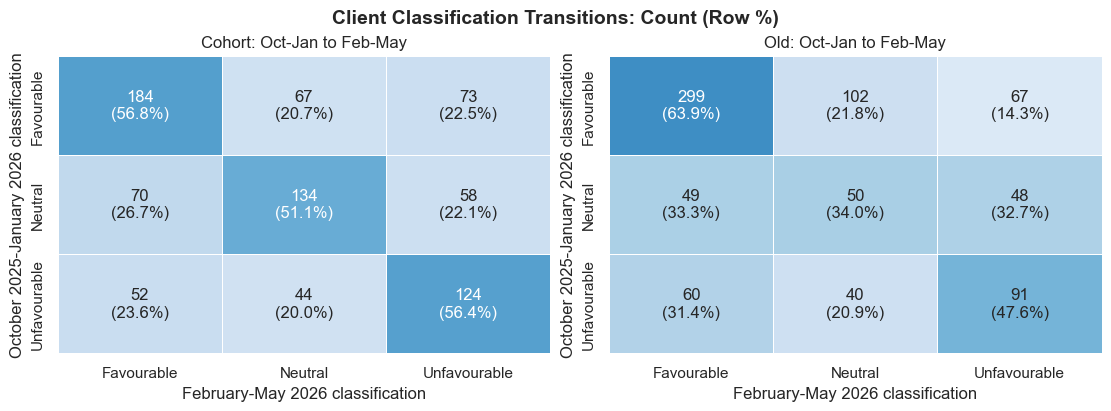

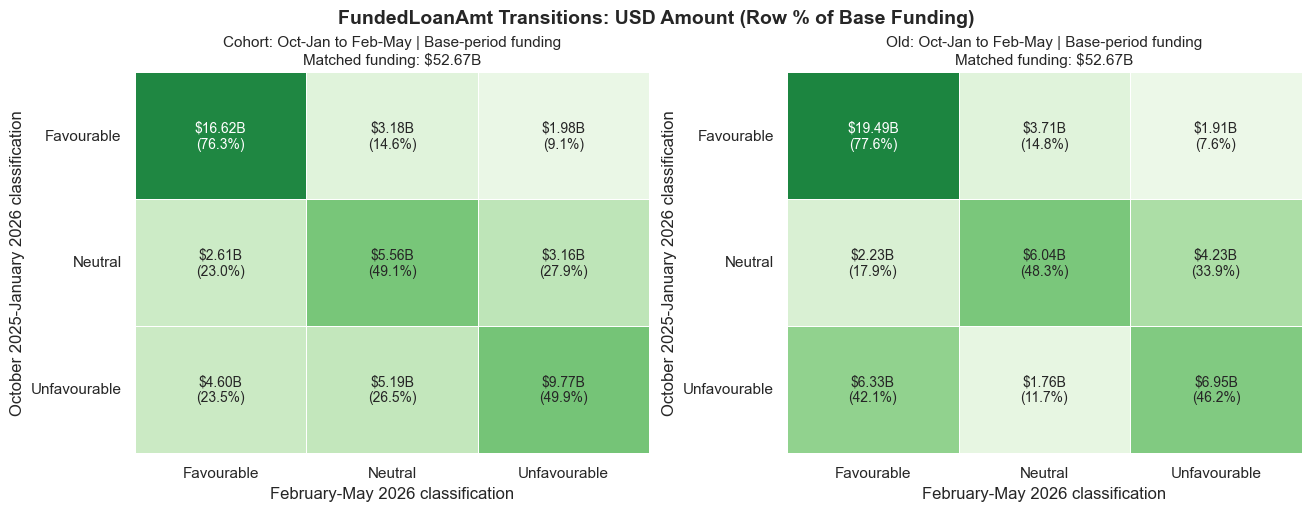

In [6]:
def transition_matrix(paired, normalize=False):
    matrix = pd.crosstab(
        paired["BaseBand"], paired["LaterBand"],
        normalize="index" if normalize else False,
    )
    return matrix.reindex(index=CLASS_ORDER, columns=CLASS_ORDER, fill_value=0)


def transition_annotations(paired):
    counts = transition_matrix(paired, normalize=False)
    percentages = transition_matrix(paired, normalize=True)
    return counts.astype(int).astype(str) + "\n(" + percentages.map(lambda value: f"{value:.1%}") + ")"


def format_funded_dollars(value):
    if pd.isna(value):
        return "N/A"
    unit, divisor = ("B", 1e9) if abs(value) >= 1e9 else ("M", 1e6)
    return f"${value / divisor:,.2f}{unit}"


def validated_funding(frame, column="FundedLoanAmt"):
    amounts = pd.to_numeric(frame[column], errors="coerce")
    if amounts.isna().any() or not np.isfinite(amounts).all() or amounts.lt(0).any():
        raise ValueError(f"{column}: funded amounts must be numeric, finite, nonmissing, and nonnegative")
    return amounts.astype(float)


def funded_cross_tab(frame, row_column, column_column, amount_column):
    if not frame[row_column].isin(CLASS_ORDER).all() or not frame[column_column].isin(CLASS_ORDER).all():
        raise ValueError("Cross-tab classifications must be Favourable, Neutral, or Unfavourable")
    amounts = validated_funding(frame, amount_column)
    dollars = frame.assign(_funded_weight=amounts).groupby(
        [row_column, column_column], observed=True,
    )["_funded_weight"].sum().unstack(column_column).reindex(index=CLASS_ORDER, columns=CLASS_ORDER).fillna(0.0)
    row_percent = dollars.div(dollars.sum(axis=1).replace(0, np.nan), axis=0)
    total = float(amounts.sum())
    portfolio_percent = dollars / total if total else dollars * np.nan
    assert np.isclose(dollars.to_numpy().sum(), total)
    assert np.allclose(row_percent.loc[dollars.sum(axis=1).gt(0)].sum(axis=1), 1)
    if total:
        assert np.isclose(portfolio_percent.to_numpy().sum(), 1)
    return dollars, row_percent, portfolio_percent


def plot_funded_matrix(frame, row_column, column_column, amount_column, axis, title):
    dollars, row_percent, portfolio_percent = funded_cross_tab(
        frame, row_column, column_column, amount_column,
    )
    annotations = dollars.map(format_funded_dollars) + "\n(" + row_percent.map(
        lambda value: "N/A" if pd.isna(value) else f"{value:.1%}"
    ) + ")"
    sns.heatmap(
        row_percent.fillna(0), annot=annotations, fmt="", cmap="Greens", vmin=0, vmax=1,
        cbar=False, linewidths=0.7, annot_kws={"fontsize": 10}, ax=axis,
    )
    axis.set_title(f"{title}\nMatched funding: {format_funded_dollars(dollars.to_numpy().sum())}", fontsize=11)
    axis.tick_params(axis="x", labelrotation=0)
    axis.tick_params(axis="y", labelrotation=0)
    return dollars, row_percent, portfolio_percent


fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for axis, (approach, paired) in zip(axes, NEXT_PAIRS.items()):
    percentages = transition_matrix(paired, normalize=True)
    annotations = transition_annotations(paired)
    sns.heatmap(percentages, annot=annotations, fmt="", cmap="Blues", vmin=0, vmax=1,
                cbar=False, linewidths=0.5, ax=axis)
    axis.set_title(f"{approach}: Oct-Jan to Feb-May")
    axis.set_xlabel(f"{CONFIG['forward_periods']['Comparison']} classification")
    axis.set_ylabel(f"{CONFIG['forward_periods']['Base']} classification")
fig.suptitle("Client Classification Transitions: Count (Row %)", fontsize=14, fontweight="bold")
fig.savefig(OUTPUT_DIR / "next_3m_transition_heatmaps.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
forward_funded_matrices = {}
for axis, (approach, paired) in zip(axes, NEXT_PAIRS.items()):
    funded_pair = paired.merge(
        FORWARD_DATA[f"{approach} Base"][[CONFIG["client_key"], "FundedLoanAmt"]],
        on=CONFIG["client_key"], how="left", validate="one_to_one",
    )
    forward_funded_matrices[approach] = plot_funded_matrix(
        funded_pair, "BaseBand", "LaterBand", "FundedLoanAmt", axis,
        f"{approach}: Oct-Jan to Feb-May | Base-period funding",
    )
    axis.set_xlabel(f"{CONFIG['forward_periods']['Comparison']} classification")
    axis.set_ylabel(f"{CONFIG['forward_periods']['Base']} classification")
fig.suptitle("FundedLoanAmt Transitions: USD Amount (Row % of Base Funding)", fontsize=14, fontweight="bold")
fig.savefig(OUTPUT_DIR / "next_3m_funded_transition_heatmaps.png", dpi=180, bbox_inches="tight")
plt.show()

## Correct Identification of Favourable and Unfavourable Clients

This view uses the full matched forward-test base population as the denominator. It reports the percentage of October-January clients whose Favourable or Unfavourable tag is retained in February-May, using the appropriate threshold for each population. This is classification agreement over time, not independent proof of predictive accuracy.

,Approach,Outcome,Correct count,Total matched clients,% of all matched clients,Base tagged count,Retention within tagged group
0,Cohort,Correctly identified Favourable,184,806,22.8%,324,56.8%
1,Cohort,Correctly identified Unfavourable,124,806,15.4%,220,56.4%
2,Old,Correctly identified Favourable,299,806,37.1%,468,63.9%
3,Old,Correctly identified Unfavourable,91,806,11.3%,191,47.6%


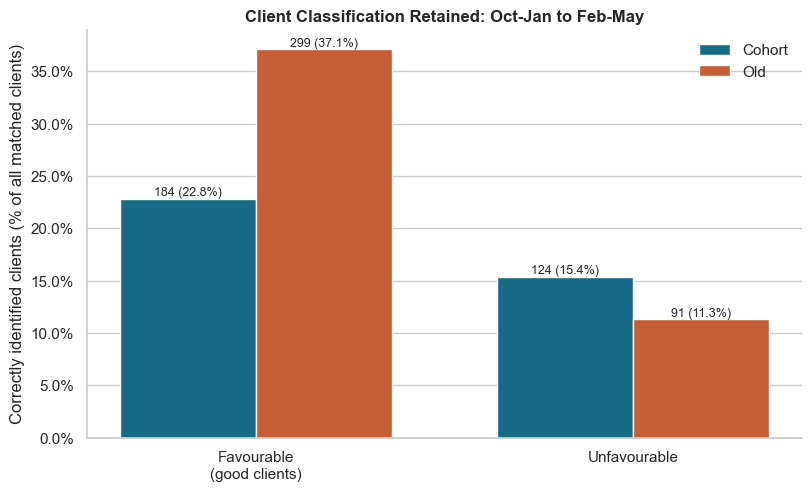

In [7]:
correct_identification_rows = []
for approach, paired in NEXT_PAIRS.items():
    total_clients = len(paired)
    for band, label in [
        ("Favourable", "Correctly identified Favourable"),
        ("Unfavourable", "Correctly identified Unfavourable"),
    ]:
        base_tagged = paired["BaseBand"].eq(band)
        correctly_identified = base_tagged & paired["LaterBand"].eq(band)
        correct_count = int(correctly_identified.sum())
        correct_identification_rows.append({
            "Approach": approach,
            "Outcome": label,
            "Correct count": correct_count,
            "Total matched clients": total_clients,
            "% of all matched clients": correct_count / total_clients,
            "Base tagged count": int(base_tagged.sum()),
            "Retention within tagged group": correct_count / base_tagged.sum() if base_tagged.any() else np.nan,
        })

correct_identification = pd.DataFrame(correct_identification_rows)
display(correct_identification.style.format({
    "Correct count": "{:,.0f}",
    "Total matched clients": "{:,.0f}",
    "% of all matched clients": "{:.1%}",
    "Base tagged count": "{:,.0f}",
    "Retention within tagged group": "{:.1%}",
}))

fig, axis = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
outcomes = ["Correctly identified Favourable", "Correctly identified Unfavourable"]
x = np.arange(len(outcomes))
width = 0.36
for offset, approach in zip([-width / 2, width / 2], ["Cohort", "Old"]):
    subset = correct_identification.set_index(["Outcome", "Approach"]).reindex(
        [(outcome, approach) for outcome in outcomes]
    )
    values = subset["% of all matched clients"].to_numpy()
    bars = axis.bar(x + offset, values, width, label=approach, color=COLORS[approach])
    for bar, value, count in zip(bars, values, subset["Correct count"]):
        axis.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{int(count)} ({value:.1%})",
            ha="center", va="bottom", fontsize=9,
        )

axis.set_xticks(x, ["Favourable\n(good clients)", "Unfavourable"])
axis.yaxis.set_major_formatter(PercentFormatter(1.0))
axis.set_ylabel("Correctly identified clients (% of all matched clients)")
axis.set_title("Client Classification Retained: Oct-Jan to Feb-May", fontweight="bold")
axis.legend(frameon=False)
axis.spines[["top", "right"]].set_visible(False)
axis.grid(axis="x", visible=False)
fig.savefig(OUTPUT_DIR / "correct_client_identification.png", dpi=180, bbox_inches="tight")
plt.show()

## 7–8. VolumeRank Deciles and Flip Comparison

Deciles are built separately for each approach and flip direction. The eligible matched base clients (base Favourable or base Unfavourable) are first sorted by base-period `VolumeRank`, then split into ten equal-count groups: D1 is the highest-volume 10% and D10 the lowest-volume 10%. When an eligible population is not divisible by ten, decile sizes differ by at most one client.

In [8]:
flip_definitions = {
    "Favourable → Neutral/Unfavourable": "Favourable",
    "Unfavourable → Neutral/Favourable": "Unfavourable",
}
decile_order = [f"D{number}" for number in range(1, CONFIG["deciles"] + 1)]
decile_rows = []

for approach, paired in NEXT_PAIRS.items():
    for flip_type, base_band in flip_definitions.items():
        eligible_clients = (
            paired.loc[paired["BaseBand"].eq(base_band)]
            .sort_values(["BaseRank", CONFIG["client_key"]])
            .copy()
        )
        eligible_clients["EligibleDecile"] = pd.qcut(
            np.arange(len(eligible_clients)),
            CONFIG["deciles"],
            labels=decile_order,
        )
        eligible_clients["Flipped"] = eligible_clients["LaterBand"].ne(base_band)

        decile_sizes = eligible_clients["EligibleDecile"].value_counts(sort=False)
        assert decile_sizes.max() - decile_sizes.min() <= 1, (
            f"{approach} {base_band} deciles are not equal-count groups: {decile_sizes.to_dict()}"
        )

        for decile, group in eligible_clients.groupby("EligibleDecile", observed=False):
            denominator = len(group)
            count = int(group["Flipped"].sum())
            decile_rows.append({
                "Approach": approach,
                "Decile": str(decile),
                "Flip direction": flip_type,
                "Flips": count,
                "Eligible base clients": denominator,
                "Flip rate": count / denominator if denominator else np.nan,
            })

decile_flips = pd.DataFrame(decile_rows)
decile_flips["Decile"] = pd.Categorical(decile_flips["Decile"], decile_order, ordered=True)
decile_flips = decile_flips.sort_values(["Flip direction", "Decile", "Approach"])

decile_table = decile_flips.pivot(
    index=["Flip direction", "Decile"],
    columns="Approach",
    values=["Flips", "Eligible base clients", "Flip rate"],
).swaplevel(0, 1, axis=1).sort_index(axis=1, level=0)
display(decile_table.style.format({
    (approach, metric): ("{:.1%}" if metric == "Flip rate" else "{:,.0f}")
    for approach in ["Cohort", "Old"]
    for metric in ["Flips", "Eligible base clients", "Flip rate"]
}))

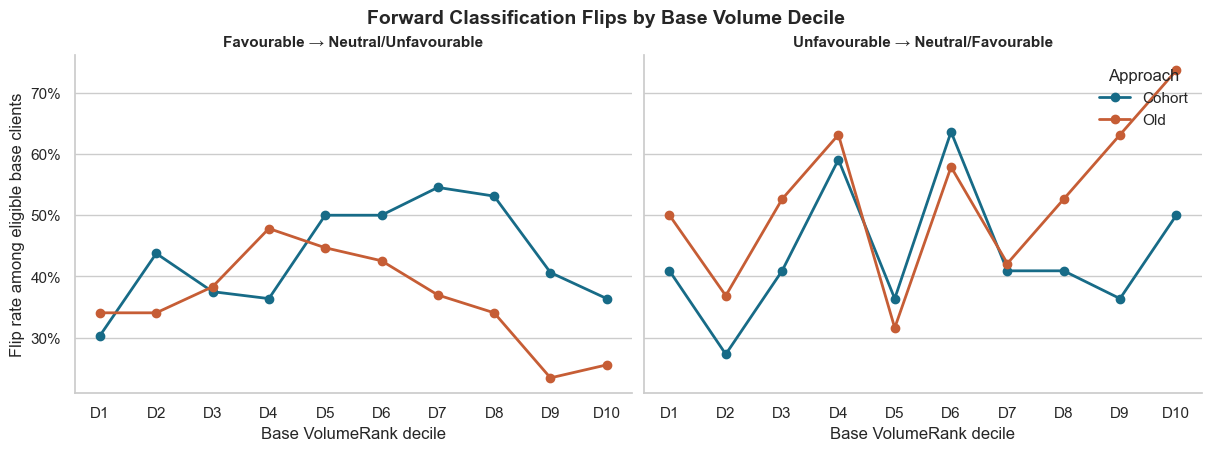

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True, constrained_layout=True)
for axis, (flip_type, base_band) in zip(axes, flip_definitions.items()):
    subset = decile_flips.loc[decile_flips["Flip direction"].eq(flip_type)]
    for approach in ["Cohort", "Old"]:
        series = subset.loc[subset["Approach"].eq(approach)].set_index("Decile").reindex(decile_order)
        axis.plot(decile_order, series["Flip rate"], marker="o", linewidth=2,
                  color=COLORS[approach], label=approach)
    axis.set_title(flip_type, fontsize=11, fontweight="bold")
    axis.set_xlabel("Base VolumeRank decile")
    axis.yaxis.set_major_formatter(PercentFormatter(1.0))
    axis.grid(axis="x", visible=False)
    axis.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Flip rate among eligible base clients")
axes[1].legend(title="Approach", frameon=False, loc="upper right")
fig.suptitle("Forward Classification Flips by Base Volume Decile", fontsize=14, fontweight="bold")
fig.savefig(OUTPUT_DIR / "decile_flip_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Old vs Cohort: Classification Comparison and Complete Reversal Details

The count heatmap compares the original base files from `CONFIG["files"]`; it is unchanged by the forward-test input selection. Rows show Cohort classifications and columns show Old classifications.

The two funded-amount heatmaps use the same matched clients and **Cohort FundedLoanAmt weights**. Both show absolute amounts in millions/billions of USD. The left matrix divides each amount by the funded total for its Cohort classification row; each nonzero row sums to 100%. The right matrix divides each amount by **total matched FundedLoanAmt**; all nine cells together sum to 100%. The denominator is the matched population, not any unmatched clients.

The grouped tables list **all clients**, not just the top ten, in both severe disagreement directions: Old Favourable / Cohort Unfavourable and Old Unfavourable / Cohort Favourable. Each table includes Volume Rank, Funded Loan Amount, CPRScore, RecapScore, TotalScore, and Classification under both approaches, sorted by the better of the two volume ranks. Separate tables cover the original base population and the October-January and February-May populations. Classification uses the configured score family and each source's own thresholds; refer to the threshold tables in Sections 3-5 and 6.

These are disagreements between approaches for the same population, not temporal flips. The forward-retention and decile sections measure temporal changes.

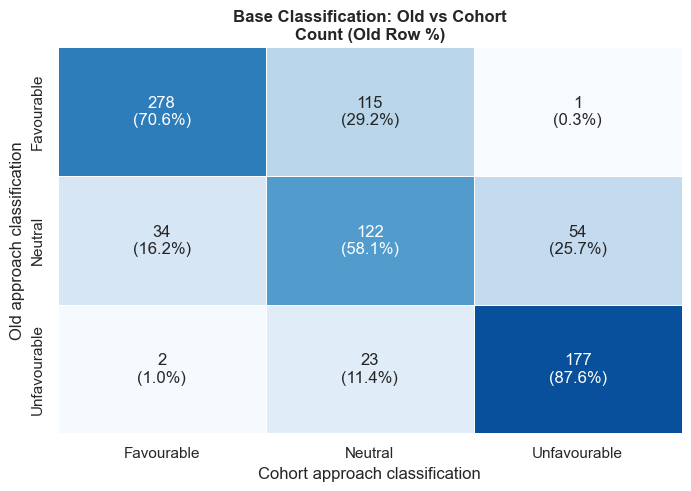

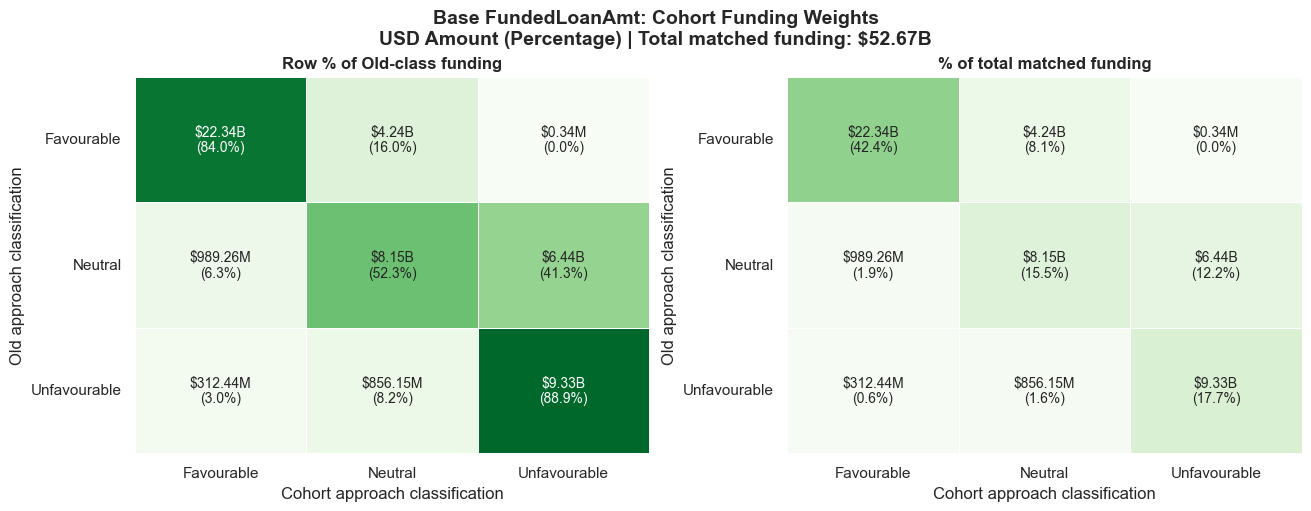

## Original Base Comparison: All Cross-Approach Reversals

### Old Unfavourable / Cohort Favourable (2 clients)

### Old Favourable / Cohort Unfavourable (1 clients)

## Forward-Test Oct-Jan: All Cross-Approach Reversals

### Old Unfavourable / Cohort Favourable (0 clients)

No clients meet this reversal definition.

### Old Favourable / Cohort Unfavourable (2 clients)

## Forward-Test Feb-May: All Cross-Approach Reversals

### Old Unfavourable / Cohort Favourable (5 clients)

### Old Favourable / Cohort Unfavourable (4 clients)

Flip-detail validation passed: all reversals included; both approaches' requested metrics match their sources.


In [10]:
key = CONFIG["client_key"]
score = CONFIG["score_column"]
rank = CONFIG["rank_column"]


def build_approach_detail(datasets, cohort_label, old_label):
    detail_columns = list(dict.fromkeys([
        key, score, "ScoreBand", rank, "FundedLoanAmt", "LoanCt",
        "CPRScore", "RecapScore", "TotalScore",
    ]))
    sources = {}
    for approach, label in [("Cohort", cohort_label), ("Old", old_label)]:
        missing = set(detail_columns) - set(datasets[label].columns)
        if missing:
            raise ValueError(f"{label}: missing flip-detail columns: {sorted(missing)}")
        source = datasets[label][detail_columns].copy()
        source = source.rename(columns={
            column: f"{approach}{column}" for column in detail_columns if column != key
        }).rename(columns={f"{approach}ScoreBand": f"{approach}Band"})
        source[f"{approach}Score"] = source[f"{approach}{score}"]
        sources[approach] = source
    result = sources["Cohort"].merge(sources["Old"], on=key, how="inner", validate="one_to_one")
    result["ComparisonVolumeRank"] = result[["CohortVolumeRank", "OldVolumeRank"]].min(axis=1)
    return result.sort_values(["ComparisonVolumeRank", key]).reset_index(drop=True)


def split_approach_flips(comparison):
    cohort_favourable = comparison["CohortBand"].eq("Favourable") & comparison["OldBand"].eq("Unfavourable")
    old_favourable = comparison["CohortBand"].eq("Unfavourable") & comparison["OldBand"].eq("Favourable")
    return (
        comparison.loc[cohort_favourable].reset_index(drop=True),
        comparison.loc[old_favourable].reset_index(drop=True),
    )


def display_approach_flips(frame, title):
    display(Markdown(f"### {title} ({len(frame):,} clients)"))
    if frame.empty:
        display(Markdown("No clients meet this reversal definition."))
        return
    metrics = [
        ("VolumeRank", "Volume Rank", "{:,.0f}"),
        ("FundedLoanAmt", "Funded Loan Amount", "${:,.0f}"),
        ("CPRScore", "CPRScore", "{:.6f}"),
        ("RecapScore", "RecapScore", "{:.6f}"),
        ("TotalScore", "TotalScore", "{:.6f}"),
        ("Band", "Classification", "{}"),
    ]
    columns = [f"{approach}{metric[0]}" for approach in ["Old", "Cohort"] for metric in metrics]
    table = frame.set_index(key)[columns].copy()
    table.index.name = "Client"
    table.columns = pd.MultiIndex.from_tuples([
        (approach, metric[1]) for approach in ["Old", "Cohort"] for metric in metrics
    ], names=["Approach", "Metric"])
    formats = {(approach, metric[1]): metric[2] for approach in ["Old", "Cohort"] for metric in metrics}
    display(table.style.format(formats, na_rep="N/A").set_table_styles([
        {"selector": "th", "props": [("padding", "8px 10px"), ("text-align", "left"),
                                       ("border-bottom", "1px solid #CBD5D9")]},
        {"selector": "td", "props": [("padding", "6px 10px"), ("text-align", "right"),
                                       ("border-bottom", "1px solid #E4E8EB")]},
        {"selector": "thead th.col_heading.level0.col0", "props": [("background-color", COLORS["Old"]), ("color", "white")]},
        {"selector": "thead th.col_heading.level0.col6", "props": [("background-color", COLORS["Cohort"]), ("color", "white")]},
    ]))


DIRECT_BASE = build_approach_detail(DATA, "Cohort Base", "Old Base")
base_approach_counts = pd.crosstab(DIRECT_BASE["OldBand"], DIRECT_BASE["CohortBand"])
base_approach_counts = base_approach_counts.reindex(index=CLASS_ORDER, columns=CLASS_ORDER, fill_value=0)
base_approach_percentages = base_approach_counts.div(base_approach_counts.sum(axis=1), axis=0)
base_approach_annotations = (
    base_approach_counts.astype(int).astype(str)
    + "\n("
    + base_approach_percentages.map(lambda value: f"{value:.1%}")
    + ")"
)

fig, axis = plt.subplots(figsize=(6.8, 4.8), constrained_layout=True)
sns.heatmap(
    base_approach_percentages, annot=base_approach_annotations, fmt="", cmap="Blues",
    vmin=0, vmax=1, cbar=False, linewidths=0.5, ax=axis,
)
axis.set_title("Base Classification: Old vs Cohort\nCount (Old Row %)", fontweight="bold")
axis.set_xlabel("Cohort approach classification")
axis.set_ylabel("Old approach classification")
fig.savefig(OUTPUT_DIR / "base_cohort_vs_old_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

base_funded_dollars, base_funded_row_percent, base_funded_total_percent = funded_cross_tab(
    DIRECT_BASE, "OldBand", "CohortBand", "CohortFundedLoanAmt",
)
assert np.allclose(base_funded_row_percent.loc[base_funded_dollars.sum(axis=1).gt(0)].sum(axis=1), 1)
if base_funded_dollars.to_numpy().sum():
    assert np.isclose(base_funded_total_percent.to_numpy().sum(), 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for axis, (label, percentages) in zip(axes, [
    ("Row % of Old-class funding", base_funded_row_percent),
    ("% of total matched funding", base_funded_total_percent),
]):
    funded_annotations = base_funded_dollars.map(format_funded_dollars) + "\n(" + percentages.map(
        lambda value: "N/A" if pd.isna(value) else f"{value:.1%}"
    ) + ")"
    sns.heatmap(
        percentages.fillna(0), annot=funded_annotations, fmt="", cmap="Greens", vmin=0, vmax=1,
        cbar=False, linewidths=0.7, annot_kws={"fontsize": 10}, ax=axis,
    )
    axis.set_title(label, fontsize=12, fontweight="bold")
    axis.set_xlabel("Cohort approach classification")
    axis.set_ylabel("Old approach classification")
    axis.tick_params(axis="both", labelrotation=0)
fig.suptitle(
    "Base FundedLoanAmt: Cohort Funding Weights\n"
    f"USD Amount (Percentage) | Total matched funding: {format_funded_dollars(base_funded_dollars.to_numpy().sum())}",
    fontsize=14, fontweight="bold",
)
fig.savefig(OUTPUT_DIR / "base_cohort_vs_old_funded_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

cohort_favourable_old_unfavourable, cohort_unfavourable_old_favourable = split_approach_flips(DIRECT_BASE)
display(Markdown("## Original Base Comparison: All Cross-Approach Reversals"))
display_approach_flips(cohort_favourable_old_unfavourable, "Old Unfavourable / Cohort Favourable")
display_approach_flips(cohort_unfavourable_old_favourable, "Old Favourable / Cohort Unfavourable")

forward_flip_details = {}
for period, cohort_label, old_label in [
    ("Oct-Jan", "Cohort Base", "Old Base"),
    ("Feb-May", "Cohort Next 3M", "Old Next 3M"),
]:
    comparison = build_approach_detail(FORWARD_DATA, cohort_label, old_label)
    favourable_flips, unfavourable_flips = split_approach_flips(comparison)
    forward_flip_details[f"{period} Cohort F Old U"] = favourable_flips
    forward_flip_details[f"{period} Cohort U Old F"] = unfavourable_flips
    display(Markdown(f"## Forward-Test {period}: All Cross-Approach Reversals"))
    display_approach_flips(favourable_flips, "Old Unfavourable / Cohort Favourable")
    display_approach_flips(unfavourable_flips, "Old Favourable / Cohort Unfavourable")
    for approach, label in [("Cohort", cohort_label), ("Old", old_label)]:
        expected = FORWARD_DATA[label].set_index(key)
        for column in [rank, "FundedLoanAmt", "CPRScore", "RecapScore", "TotalScore"]:
            pd.testing.assert_series_equal(
                comparison.set_index(key)[f"{approach}{column}"].sort_index(),
                expected.loc[comparison[key], column].sort_index(), check_names=False,
            )
assert len(cohort_favourable_old_unfavourable) == int(
    (DIRECT_BASE["CohortBand"].eq("Favourable") & DIRECT_BASE["OldBand"].eq("Unfavourable")).sum()
)
assert len(cohort_unfavourable_old_favourable) == int(
    (DIRECT_BASE["CohortBand"].eq("Unfavourable") & DIRECT_BASE["OldBand"].eq("Favourable")).sum()
)
print("Flip-detail validation passed: all reversals included; both approaches' requested metrics match their sources.")

## 11A. Base TotalScore Distribution and Severe Disagreements

Both approaches are plotted at the same client position, ordered by Cohort base VolumeRank (Old rank is used for Old-only clients). This section always uses **TotalScore**, independently of `score_column`; higher TotalScore is Favourable. Each approach uses its own base-file portfolio TotalScore as Z, with the configured multipliers. Favourable includes the upper cutoff; Unfavourable is strictly below the lower cutoff. Colored dashed and dotted lines mark each approach's upper and lower cutoffs, respectively, with exact values in the side panel.

Missing, blank, nonnumeric, and nonfinite scores are excluded separately for each approach. Band counts include every valid base score; severe disagreements require a valid score from both approaches. Triangles identify Cohort Favourable / Old Unfavourable clients; squares identify the reverse. Connecting lines join the two scores for each highlighted client. The side panel lists the highest-volume examples by plot position, and the table below lists every severe disagreement.

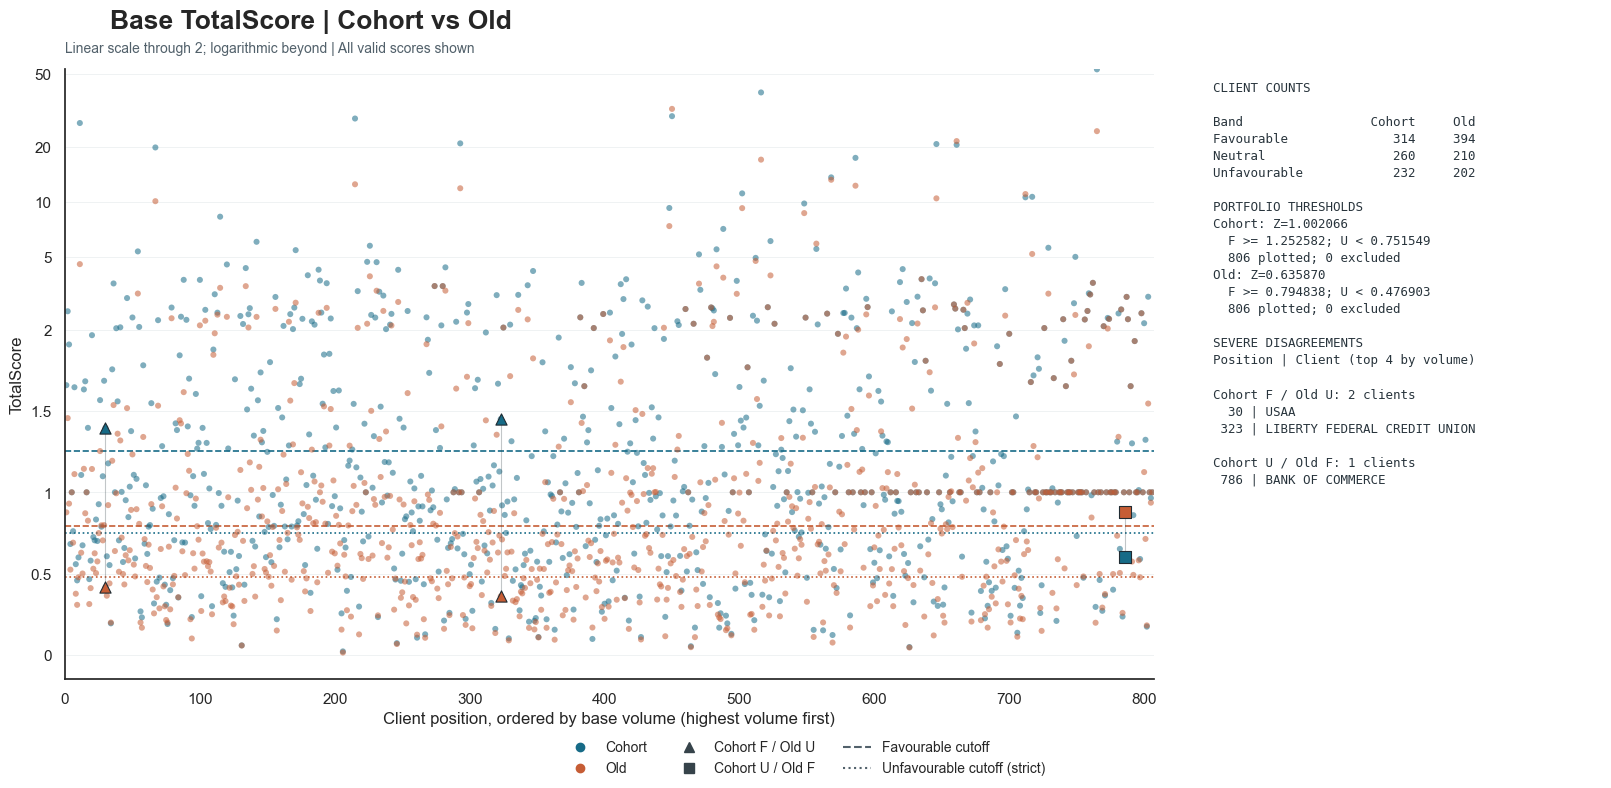

,Cohort,Old
TotalScore band,,
Favourable,314,394
Neutral,260,210
Unfavourable,232,202


### All Severe TotalScore Disagreements

,MetricValue,ClientPosition,PlotVolumeRank,CohortTotalScore,OldTotalScore,SevereDisagreement
29,USAA,30,30,1.397,0.418,Cohort F / Old U
322,LIBERTY FEDERAL CREDIT UNION,323,323,1.450,0.360,Cohort F / Old U
785,BANK OF COMMERCE,786,786,0.605,0.880,Cohort U / Old F


TotalScore chart validation passed: per-file Z, invalid-score exclusions, and exact boundaries.


In [11]:
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter
import textwrap


def prepare_total_score_base(frame, approach, thresholds=None):
    client_key = CONFIG["client_key"]
    required = {"MetricName", client_key, "TotalScore", CONFIG["rank_column"]}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{approach} Base: missing columns: {sorted(missing)}")
    if thresholds is None:
        thresholds = derive_score_thresholds(frame, f"{approach} Base", "TotalScore")
    clients = frame.loc[frame["MetricName"].eq(CONFIG["metric_name"]),
                        [client_key, "TotalScore", CONFIG["rank_column"]]].copy()
    if clients[client_key].isna().any() or clients[client_key].duplicated().any():
        raise ValueError(f"{approach} Base: missing or duplicate client identifiers")
    numeric_scores = pd.to_numeric(clients["TotalScore"], errors="coerce")
    valid_scores = np.isfinite(numeric_scores.to_numpy(dtype=float, na_value=np.nan))
    clients["TotalScore"] = numeric_scores.where(valid_scores)
    clients["TotalScoreBand"] = assign_score_band(
        clients["TotalScore"], thresholds["Upper threshold"],
        thresholds["Lower threshold"], "higher_is_favourable",
    ).where(valid_scores)
    clients.attrs["thresholds"] = thresholds
    return clients.rename(columns={
        "TotalScore": f"{approach}TotalScore",
        "TotalScoreBand": f"{approach}TotalScoreBand",
        CONFIG["rank_column"]: f"{approach}BaseVolumeRank",
    })


total_score_sources = {
    approach: prepare_total_score_base(
        pd.read_excel(ROOT / CONFIG["files"][f"{approach} Base"],
                      sheet_name=CONFIG["sheet_name"]), approach,
    )
    for approach in ["Cohort", "Old"]
}
total_score_thresholds = {
    approach: source.attrs["thresholds"] for approach, source in total_score_sources.items()
}
total_score_comparison = total_score_sources["Cohort"].merge(
    total_score_sources["Old"], on=CONFIG["client_key"], how="outer", validate="one_to_one",
)
total_score_comparison["PlotVolumeRank"] = total_score_comparison["CohortBaseVolumeRank"].combine_first(
    total_score_comparison["OldBaseVolumeRank"]
)
total_score_comparison = total_score_comparison.sort_values(
    ["PlotVolumeRank", CONFIG["client_key"]], na_position="last",
).reset_index(drop=True)
total_score_comparison["ClientPosition"] = np.arange(1, len(total_score_comparison) + 1)
total_score_comparison["SevereDisagreement"] = np.select(
    [
        total_score_comparison["CohortTotalScoreBand"].eq("Favourable")
        & total_score_comparison["OldTotalScoreBand"].eq("Unfavourable"),
        total_score_comparison["CohortTotalScoreBand"].eq("Unfavourable")
        & total_score_comparison["OldTotalScoreBand"].eq("Favourable"),
    ],
    ["Cohort F / Old U", "Cohort U / Old F"], default="",
)
total_score_band_counts = pd.DataFrame({
    approach: total_score_sources[approach][f"{approach}TotalScoreBand"].value_counts().reindex(
        CLASS_ORDER, fill_value=0,
    )
    for approach in ["Cohort", "Old"]
})
total_score_band_counts.index.name = "TotalScore band"
total_score_disagreements = total_score_comparison.loc[
    total_score_comparison["SevereDisagreement"].ne("")
].copy()
valid_total_scores = pd.concat([
    total_score_comparison[f"{approach}TotalScore"].dropna() for approach in ["Cohort", "Old"]
])
if valid_total_scores.empty:
    raise ValueError("No valid base TotalScore values are available to plot.")

threshold_values = [
    thresholds[column]
    for thresholds in total_score_thresholds.values()
    for column in ["Lower threshold", "Upper threshold"]
]
score_min = min(valid_total_scores.min(), min(threshold_values))
score_max = max(valid_total_scores.max(), max(threshold_values))
linear_limit = max(2.0, max(abs(value) for value in threshold_values) * 1.2)
use_compressed_scale = max(abs(score_min), abs(score_max)) > linear_limit * 3
score_padding = 0.08 * linear_limit if use_compressed_scale else max((score_max - score_min) * 0.07, 0.05)

with sns.axes_style("white"):
    fig = plt.figure(figsize=(16, 7.8), layout="constrained", facecolor="white")
    grid = fig.add_gridspec(1, 2, width_ratios=[3.5, 1.25], wspace=0.07)
    scatter_axis = fig.add_subplot(grid[0, 0])
    detail_axis = fig.add_subplot(grid[0, 1])
    detail_axis.set_axis_off()
    if use_compressed_scale:
        scatter_axis.set_yscale("symlog", linthresh=linear_limit, linscale=1.6)
        tick_candidates = sorted(set([0, 0.5, 1, 1.5, linear_limit]
                                     + [sign * value for sign in [-1, 1] for value in [5, 10, 20, 50, 100, 200, 500, 1000]]))
        scatter_axis.set_yticks([value for value in tick_candidates if score_min - score_padding <= value <= score_max + score_padding])
        scatter_axis.yaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    for approach, thresholds in total_score_thresholds.items():
        for column, style in [("Upper threshold", "--"), ("Lower threshold", ":")]:
            scatter_axis.axhline(thresholds[column], color=COLORS[approach], linestyle=style,
                                 linewidth=1.2, zorder=1)
    for approach in ["Cohort", "Old"]:
        valid = total_score_comparison[f"{approach}TotalScore"].notna()
        scatter_axis.scatter(
            total_score_comparison.loc[valid, "ClientPosition"],
            total_score_comparison.loc[valid, f"{approach}TotalScore"],
            s=19, color=COLORS[approach], alpha=0.55, edgecolors="none", zorder=2,
        )
    highlight_styles = [("Cohort F / Old U", "^"), ("Cohort U / Old F", "s")]
    for direction, marker in highlight_styles:
        highlighted = total_score_disagreements.loc[
            total_score_disagreements["SevereDisagreement"].eq(direction)
        ]
        segments = [
            [(position, cohort_score), (position, old_score)]
            for position, cohort_score, old_score in highlighted[
                ["ClientPosition", "CohortTotalScore", "OldTotalScore"]
            ].itertuples(index=False, name=None)
        ]
        scatter_axis.add_collection(LineCollection(segments, colors="#36434A", linewidths=0.8, alpha=0.3, zorder=3))
        for approach in ["Cohort", "Old"]:
            scatter_axis.scatter(highlighted["ClientPosition"], highlighted[f"{approach}TotalScore"],
                                 marker=marker, s=65, color=COLORS[approach], edgecolors="#202B32",
                                 linewidths=0.8, zorder=4)
    scatter_axis.set(xlim=(0, len(total_score_comparison) + 1),
                     ylim=(score_min - score_padding, score_max + score_padding),
                     xlabel="Client position, ordered by base volume (highest volume first)", ylabel="TotalScore")
    if use_compressed_scale:
        scatter_axis.set_title(f"Linear scale through {linear_limit:g}; logarithmic beyond | All valid scores shown",
                               loc="left", fontsize=10, color="#52616B", pad=12)
    scatter_axis.grid(axis="y", color="#D6DDE1", alpha=0.45, linewidth=0.6)
    scatter_axis.spines[["top", "right"]].set_visible(False)
    legend_handles = [
        Line2D([], [], marker="o", linestyle="none", color=COLORS[approach], label=approach, markersize=6)
        for approach in ["Cohort", "Old"]
    ] + [
        Line2D([], [], marker=marker, linestyle="none", color="#36434A", label=direction, markersize=7)
        for direction, marker in highlight_styles
    ] + [
        Line2D([], [], linestyle=style, color="#52616B", label=label)
        for style, label in [("--", "Favourable cutoff"), (":", "Unfavourable cutoff (strict)")]
    ]
    fig.legend(handles=legend_handles, loc="outside lower center", ncol=3, frameon=False, fontsize=10)
    fig.suptitle("Base TotalScore | Cohort vs Old", fontsize=19, fontweight="bold", ha="left", x=0.065)
    panel_lines = ["CLIENT COUNTS", "", "Band                 Cohort     Old"]
    for band in CLASS_ORDER:
        counts = total_score_band_counts.loc[band]
        panel_lines.append(f"{band:<20} {counts['Cohort']:>6,} {counts['Old']:>7,}")
    panel_lines += ["", "PORTFOLIO THRESHOLDS"]
    for approach in ["Cohort", "Old"]:
        source = total_score_sources[approach]
        thresholds = total_score_thresholds[approach]
        valid_count = int(source[f"{approach}TotalScore"].notna().sum())
        panel_lines.append(f"{approach}: Z={thresholds['Z']:.6f}")
        panel_lines.append(f"  F >= {thresholds['Upper threshold']:.6f}; U < {thresholds['Lower threshold']:.6f}")
        panel_lines.append(f"  {valid_count:,} plotted; {len(source) - valid_count:,} excluded")
    panel_lines += ["", "SEVERE DISAGREEMENTS", "Position | Client (top 4 by volume)"]
    for direction, marker in highlight_styles:
        highlighted = total_score_disagreements.loc[total_score_disagreements["SevereDisagreement"].eq(direction)]
        panel_lines += ["", f"{direction}: {len(highlighted):,} clients"]
        for position, client in highlighted[["ClientPosition", CONFIG["client_key"]]].head(4).itertuples(index=False, name=None):
            panel_lines.append(f"{position:>4} | {textwrap.shorten(str(client), width=28, placeholder='...')}")
        if highlighted.empty:
            panel_lines.append("None")
    detail_axis.text(0, 0.98, "\n".join(panel_lines), transform=detail_axis.transAxes,
                     va="top", fontsize=9, fontfamily="DejaVu Sans Mono", color="#28343C", linespacing=1.4)
    fig.savefig(OUTPUT_DIR / "base_total_score_scatter.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

display(total_score_band_counts)
display(Markdown("### All Severe TotalScore Disagreements"))
display(total_score_disagreements[[
    CONFIG["client_key"], "ClientPosition", "PlotVolumeRank", "CohortTotalScore", "OldTotalScore",
    "SevereDisagreement",
]].style.format({"CohortTotalScore": "{:.3f}", "OldTotalScore": "{:.3f}", "PlotVolumeRank": "{:,.0f}"}))
assert total_score_band_counts.sum().to_dict() == {
    approach: int(total_score_sources[approach][f"{approach}TotalScore"].notna().sum())
    for approach in ["Cohort", "Old"]
}
assert total_score_disagreements[["CohortTotalScore", "OldTotalScore"]].notna().all().all()
for approach, thresholds in total_score_thresholds.items():
    lower_threshold = thresholds["Lower threshold"]
    upper_threshold = thresholds["Upper threshold"]
    total_score_test_values = [None, "", " ", "invalid", np.inf, -np.inf, 0,
                              np.nextafter(lower_threshold, -np.inf), lower_threshold, upper_threshold]
    total_score_test_frame = pd.DataFrame({
        "MetricName": [CONFIG["metric_name"]] * len(total_score_test_values),
        CONFIG["client_key"]: [f"test-{number}" for number in range(len(total_score_test_values))],
        CONFIG["rank_column"]: np.arange(1, len(total_score_test_values) + 1),
        "TotalScore": total_score_test_values,
    })
    total_score_test_result = prepare_total_score_base(total_score_test_frame, approach, thresholds)
    assert total_score_test_result[f"{approach}TotalScore"].iloc[:6].isna().all()
    assert total_score_test_result[f"{approach}TotalScoreBand"].iloc[:6].isna().all()
    assert total_score_test_result[f"{approach}TotalScore"].iloc[6] == 0
    assert total_score_test_result[f"{approach}TotalScoreBand"].iloc[7:].tolist() == ["Unfavourable", "Neutral", "Favourable"]
    if CONFIG["score_column"] == "TotalScore" and resolved_direction == "higher_is_favourable":
        expected_bands = DATA[f"{approach} Base"].set_index(CONFIG["client_key"])["ScoreBand"].sort_index()
        chart_bands = total_score_sources[approach].set_index(CONFIG["client_key"])[f"{approach}TotalScoreBand"].sort_index()
        pd.testing.assert_series_equal(chart_bands, expected_bands, check_names=False)
print("TotalScore chart validation passed: per-file Z, invalid-score exclusions, and exact boundaries.")

In [12]:
top25_client_key = CONFIG["client_key"]
top25_rank_column = CONFIG["rank_column"]
top25_score_columns = ["CPRScore", "RecapScore", "TotalScore"]
top25_base_frames = {}

for top25_approach in ["Cohort", "Old"]:
    top25_raw = pd.read_excel(
        ROOT / CONFIG["files"][f"{top25_approach} Base"],
        sheet_name=CONFIG["sheet_name"],
    )
    top25_required = {"MetricName", top25_client_key, top25_rank_column, *top25_score_columns}
    top25_missing = top25_required - set(top25_raw.columns)
    if top25_missing:
        raise ValueError(f"{top25_approach} Base: missing columns: {sorted(top25_missing)}")
    top25_clients = top25_raw.loc[
        top25_raw["MetricName"].eq(CONFIG["metric_name"]),
        [top25_client_key, top25_rank_column, *top25_score_columns],
    ].copy()
    if top25_clients[top25_client_key].isna().any() or top25_clients[top25_client_key].duplicated().any():
        raise ValueError(f"{top25_approach} Base: missing or duplicate lender identifiers")
    top25_clients[top25_rank_column] = pd.to_numeric(top25_clients[top25_rank_column], errors="coerce")
    if not np.isfinite(top25_clients[top25_rank_column]).all():
        raise ValueError(f"{top25_approach} Base: missing or invalid VolumeRank")
    for top25_score_column in top25_score_columns:
        top25_numeric = pd.to_numeric(top25_clients[top25_score_column], errors="coerce")
        top25_clients[top25_score_column] = top25_numeric.where(np.isfinite(top25_numeric))
    top25_base_frames[top25_approach] = top25_clients.rename(columns={
        column: f"{top25_approach} {column}"
        for column in [top25_rank_column, *top25_score_columns]
    })

top25_selected = top25_base_frames["Cohort"].sort_values(
    [f"Cohort {top25_rank_column}", top25_client_key],
).head(25)
top25_lender_summary = top25_selected.merge(
    top25_base_frames["Old"], on=top25_client_key, how="left", validate="one_to_one", indicator=True,
).sort_values([f"Cohort {top25_rank_column}", top25_client_key]).reset_index(drop=True)
top25_unmatched_count = int(top25_lender_summary["_merge"].eq("left_only").sum())
top25_lender_summary = top25_lender_summary.drop(columns="_merge")
assert len(top25_lender_summary) == min(25, len(top25_base_frames["Cohort"]))
assert top25_lender_summary[top25_client_key].tolist() == top25_selected[top25_client_key].tolist()

top25_display_columns = [
    f"{approach} {column}"
    for approach in ["Cohort", "Old"]
    for column in [top25_rank_column, *top25_score_columns]
]
top25_display = top25_lender_summary.set_index(top25_client_key)[top25_display_columns].copy()
top25_display.index.name = "Lender"
top25_display.columns = pd.MultiIndex.from_product(
    [["Cohort", "Old"], [top25_rank_column, *top25_score_columns]], names=["Approach", "Metric"],
)
display(Markdown(
    "## 11B. Top 25 Lenders: Base Score Comparison\n\n"
    "Selected by **Cohort Base VolumeRank**, ascending (highest volume first). "
    "The same lenders are matched to Old Base; both ranks are shown. "
    "Missing or invalid scores are displayed as N/A."
))
display(top25_display.style.format({
    (approach, column): "{:,.0f}" if column == top25_rank_column else "{:.3f}"
    for approach in ["Cohort", "Old"]
    for column in [top25_rank_column, *top25_score_columns]
}, na_rep="N/A").set_table_styles([
    {"selector": "", "props": [("background-color", "#202428"), ("color", "#F1F5F9"), ("border-collapse", "collapse")]},
    {"selector": "th", "props": [("text-align", "left"), ("color", "#F1F5F9"), ("background-color", "#353D45"), ("padding", "8px 12px"), ("border-bottom", "1px solid #4B5563")]},
    {"selector": "td", "props": [("text-align", "right"), ("color", "#F1F5F9"), ("background-color", "#202428"), ("padding", "6px 12px"), ("border-bottom", "1px solid #3A424A")]},
    {"selector": "tbody th", "props": [("background-color", "#202428"), ("font-weight", "500")]},
    {"selector": "tbody tr:nth-child(even) th, tbody tr:nth-child(even) td", "props": [("background-color", "#2A3036"), ("color", "#F1F5F9")]},
    {"selector": "thead th.col_heading.level0.col0", "props": [("background-color", "#14566D"), ("color", "#FFFFFF")]},
    {"selector": "thead th.col_heading.level0.col4", "props": [("background-color", "#854025"), ("color", "#FFFFFF")]},
]))
if top25_unmatched_count:
    print(f"{top25_unmatched_count} selected lenders have no matching Old Base row; Old values are N/A.")

## 11B. Top 25 Lenders: Base Score Comparison

Selected by **Cohort Base VolumeRank**, ascending (highest volume first). The same lenders are matched to Old Base; both ranks are shown. Missing or invalid scores are displayed as N/A.

In [13]:
def classification_distribution(frame):
    if not frame["ScoreBand"].isin(CLASS_ORDER).all():
        raise ValueError("Distribution classifications must be Favourable, Neutral, or Unfavourable")
    amounts = validated_funding(frame)
    counts = frame["ScoreBand"].value_counts().reindex(CLASS_ORDER, fill_value=0)
    dollars = amounts.groupby(frame["ScoreBand"]).sum().reindex(CLASS_ORDER, fill_value=0.0)
    result = pd.DataFrame({
        "Clients": counts,
        "Client %": counts / len(frame) if len(frame) else counts * np.nan,
        "FundedLoanAmt": dollars,
        "Funded %": dollars / amounts.sum() if amounts.sum() else dollars * np.nan,
    }).rename_axis("Classification")
    assert result["Clients"].sum() == len(frame)
    assert np.isclose(result["FundedLoanAmt"].sum(), amounts.sum())
    if len(frame):
        assert np.isclose(result["Client %"].sum(), 1)
    if amounts.sum():
        assert np.isclose(result["Funded %"].sum(), 1)
    return result


def style_funded_table(table, formats):
    return table.style.format(formats, na_rep="N/A").set_table_styles([
        {"selector": "", "props": [("background-color", "#202428"), ("color", "#F1F5F9"), ("border-collapse", "collapse")]},
        {"selector": "th", "props": [("background-color", "#353D45"), ("color", "#F1F5F9"), ("text-align", "left"), ("padding", "8px 10px")]},
        {"selector": "td", "props": [("background-color", "#202428"), ("color", "#F1F5F9"), ("text-align", "right"), ("padding", "7px 10px")]},
        {"selector": "tbody th", "props": [("background-color", "#202428")]},
        {"selector": "tbody tr:nth-child(even) th, tbody tr:nth-child(even) td", "props": [("background-color", "#2A3036")]},
    ])


funding_test = pd.DataFrame({
    "BaseBand": ["Favourable", "Favourable", "Neutral", "Unfavourable"],
    "LaterBand": ["Favourable", "Neutral", "Unfavourable", "Favourable"],
    "FundedLoanAmt": [100e6, 300e6, 0, 600e6],
})
funding_test_dollars, funding_test_rows, funding_test_total = funded_cross_tab(
    funding_test, "BaseBand", "LaterBand", "FundedLoanAmt",
)
assert funding_test_dollars.loc["Favourable", "Neutral"] == 300e6
assert funding_test_rows.loc["Favourable", "Neutral"] == 0.75
assert funding_test_total.loc["Favourable", "Neutral"] == 0.3
assert funding_test_rows.loc["Neutral"].isna().all()
funding_test_distribution = classification_distribution(funding_test.rename(columns={"BaseBand": "ScoreBand"}))
assert funding_test_distribution.loc["Favourable", "Client %"] == 0.5
assert funding_test_distribution.loc["Favourable", "Funded %"] == 0.4
assert funded_cross_tab(funding_test.assign(FundedLoanAmt=0), "BaseBand", "LaterBand", "FundedLoanAmt")[2].isna().all().all()
assert funded_cross_tab(funding_test.iloc[:0], "BaseBand", "LaterBand", "FundedLoanAmt")[0].shape == (3, 3)
assert format_funded_dollars(1.5e9) == "$1.50B"
assert format_funded_dollars(250e6) == "$250.00M"
print("Funded-view checks passed: dollar reconciliation, percentage denominators, zero funding, empty matrices, and M/B formatting.")

Funded-view checks passed: dollar reconciliation, percentage denominators, zero funding, empty matrices, and M/B formatting.


In [14]:
display(Markdown(
    "## 11C. Classification Mix and Funded-Dollar Cross-Tabs\n\n"
    "**Distributions:** all clients in each source; each approach has its own client and funded-dollar denominators. "
    "**Cross-tabs:** matched clients only. Forward transitions use base-period FundedLoanAmt; "
    "same-period Cohort-versus-Old tables are shown using each approach's funding weights separately. "
    "Row % divides by funded dollars in that row; Portfolio % divides by all matched funded dollars in that view. "
    "M = million USD; B = billion USD. Zero-funded denominators display N/A."
))
funded_populations = [
    ("Original Base", DATA, "Cohort Base", "Old Base"),
    (CONFIG["forward_periods"]["Base"], FORWARD_DATA, "Cohort Base", "Old Base"),
    (CONFIG["forward_periods"]["Comparison"], FORWARD_DATA, "Cohort Next 3M", "Old Next 3M"),
]
classification_mix_tables = {}
classification_mix_records = []
for population, datasets, cohort_label, old_label in funded_populations:
    mix_parts = {}
    for approach, source_label in [("Cohort", cohort_label), ("Old", old_label)]:
        mix = classification_distribution(datasets[source_label])
        mix_parts[approach] = mix
        classification_mix_records.append(mix.reset_index().assign(
            Population=population, Approach=approach, Source=source_label,
        ))
    mix_table = pd.concat(mix_parts, axis=1)
    classification_mix_tables[population] = mix_table
    display(Markdown(f"### Classification Distribution: {population}"))
    display(style_funded_table(mix_table, {
        (approach, metric): (
            format_funded_dollars if metric == "FundedLoanAmt"
            else "{:,.0f}" if metric == "Clients" else "{:.1%}"
        )
        for approach in ["Cohort", "Old"]
        for metric in ["Clients", "Client %", "FundedLoanAmt", "Funded %"]
    }))
classification_mix = pd.concat(classification_mix_records, ignore_index=True)
funded_cross_tabs = {}
funded_cross_tab_records = []
funded_coverage_records = []


def show_funded_cross_tab(view, left_source, right_source, left_name, right_name, weight_sources):
    client_key = CONFIG["client_key"]
    left = left_source[[client_key, "ScoreBand", "FundedLoanAmt"]].rename(columns={
        "ScoreBand": left_name, "FundedLoanAmt": "LeftFundedLoanAmt",
    })
    right = right_source[[client_key, "ScoreBand", "FundedLoanAmt"]].rename(columns={
        "ScoreBand": right_name, "FundedLoanAmt": "RightFundedLoanAmt",
    })
    matched = left.merge(right, on=client_key, how="inner", validate="one_to_one")
    if matched.empty:
        raise ValueError(f"{view}: no matched clients available for funded cross-tabs")
    for weight_name, amount_column, source in weight_sources:
        dollars, row_percent, portfolio_percent = funded_cross_tab(
            matched, left_name, right_name, amount_column,
        )
        source_total = float(validated_funding(source).sum())
        matched_total = float(validated_funding(matched, amount_column).sum())
        coverage = matched_total / source_total if source_total else np.nan
        funded_coverage_records.append({
            "View": view, "Weight basis": weight_name,
            "Source clients": len(source), "Matched clients": len(matched),
            "Source FundedLoanAmt": source_total, "Matched FundedLoanAmt": matched_total,
            "Funded coverage %": coverage,
        })
        funded_cross_tabs[(view, weight_name)] = {
            "FundedLoanAmt": dollars, "Row %": row_percent, "Portfolio %": portfolio_percent,
        }
        table = pd.concat(funded_cross_tabs[(view, weight_name)], axis=1)
        display(Markdown(
            f"### {view} | {weight_name}\n\n"
            f"Rows: **{left_name}**; columns: **{right_name}**. "
            f"Matched clients: **{len(matched):,}**; matched funded amount: **{format_funded_dollars(matched_total)}**; "
            f"funded coverage: **{coverage:.1%}** of the weighting source."
        ))
        display(style_funded_table(table, {
            (metric, band): format_funded_dollars if metric == "FundedLoanAmt" else "{:.1%}"
            for metric in ["FundedLoanAmt", "Row %", "Portfolio %"] for band in CLASS_ORDER
        }))
        for row_band in CLASS_ORDER:
            for column_band in CLASS_ORDER:
                funded_cross_tab_records.append({
                    "View": view, "Weight basis": weight_name,
                    "Row axis": left_name, "Column axis": right_name,
                    "Row classification": row_band, "Column classification": column_band,
                    "FundedLoanAmt": dollars.loc[row_band, column_band],
                    "Row %": row_percent.loc[row_band, column_band],
                    "Portfolio %": portfolio_percent.loc[row_band, column_band],
                })


for approach in ["Cohort", "Old"]:
    base_source = FORWARD_DATA[f"{approach} Base"]
    show_funded_cross_tab(
        f"{approach} Forward: Oct-Jan to Feb-May", base_source, FORWARD_DATA[f"{approach} Next 3M"],
        "Base classification", "Later classification",
        [("Base-period funding", "LeftFundedLoanAmt", base_source)],
    )

for population, datasets, cohort_label, old_label in funded_populations:
    cohort_source, old_source = datasets[cohort_label], datasets[old_label]
    show_funded_cross_tab(
        f"Cohort vs Old: {population}", cohort_source, old_source,
        "Cohort classification", "Old classification",
        [("Cohort funding", "LeftFundedLoanAmt", cohort_source),
         ("Old funding", "RightFundedLoanAmt", old_source)],
    )
funded_cross_tab_summary = pd.DataFrame(funded_cross_tab_records)
funded_match_coverage = pd.DataFrame(funded_coverage_records)
assert len(funded_cross_tabs) == 8
assert len(classification_mix) == 18

funded_output_workbook = OUTPUT_DIR / "b2b_funded_amount_views.xlsx"
with pd.ExcelWriter(funded_output_workbook, engine="openpyxl") as funded_writer:
    classification_mix.to_excel(funded_writer, sheet_name="Classification Mix", index=False)
    funded_cross_tab_summary.to_excel(funded_writer, sheet_name="Funded Cross Tabs", index=False)
    funded_match_coverage.to_excel(funded_writer, sheet_name="Matched Funding Coverage", index=False)
    for funded_sheet in funded_writer.sheets.values():
        funded_sheet.freeze_panes = "B2"
        funded_sheet.auto_filter.ref = funded_sheet.dimensions
        for funded_header in funded_sheet[1]:
            funded_name = str(funded_header.value)
            funded_sheet.column_dimensions[funded_header.column_letter].width = 34
            for funded_cells in funded_sheet.iter_rows(min_row=2, min_col=funded_header.column, max_col=funded_header.column):
                funded_cell = funded_cells[0]
                if "FundedLoanAmt" in funded_name:
                    funded_cell.number_format = '[>=1000000000]"$"0.00,,,"B";[>=1000000]"$"0.00,,"M";"$"0.00'
                elif "%" in funded_name:
                    funded_cell.number_format = "0.0%"
exported_funded_mix = pd.read_excel(funded_output_workbook, sheet_name="Classification Mix")
exported_funded_cross_tabs = pd.read_excel(funded_output_workbook, sheet_name="Funded Cross Tabs")
pd.testing.assert_frame_equal(exported_funded_mix, classification_mix, check_dtype=False)
pd.testing.assert_frame_equal(exported_funded_cross_tabs, funded_cross_tab_summary, check_dtype=False)
print(f"Validated 8 funded cross-tabs and 6 population distributions. Export: {funded_output_workbook}")

## 11C. Classification Mix and Funded-Dollar Cross-Tabs

**Distributions:** all clients in each source; each approach has its own client and funded-dollar denominators. **Cross-tabs:** matched clients only. Forward transitions use base-period FundedLoanAmt; same-period Cohort-versus-Old tables are shown using each approach's funding weights separately. Row % divides by funded dollars in that row; Portfolio % divides by all matched funded dollars in that view. M = million USD; B = billion USD. Zero-funded denominators display N/A.

### Classification Distribution: Original Base

### Classification Distribution: October 2025-January 2026

### Classification Distribution: February-May 2026

### Cohort Forward: Oct-Jan to Feb-May | Base-period funding

Rows: **Base classification**; columns: **Later classification**. Matched clients: **806**; matched funded amount: **$52.67B**; funded coverage: **100.0%** of the weighting source.

### Old Forward: Oct-Jan to Feb-May | Base-period funding

Rows: **Base classification**; columns: **Later classification**. Matched clients: **806**; matched funded amount: **$52.67B**; funded coverage: **100.0%** of the weighting source.

... (3 outputs left out)

### Cohort vs Old: October 2025-January 2026 | Old funding

Rows: **Cohort classification**; columns: **Old classification**. Matched clients: **806**; matched funded amount: **$52.67B**; funded coverage: **100.0%** of the weighting source.

### Cohort vs Old: February-May 2026 | Cohort funding

Rows: **Cohort classification**; columns: **Old classification**. Matched clients: **806**; matched funded amount: **$52.67B**; funded coverage: **100.0%** of the weighting source.

### Cohort vs Old: February-May 2026 | Old funding

Rows: **Cohort classification**; columns: **Old classification**. Matched clients: **806**; matched funded amount: **$52.67B**; funded coverage: **100.0%** of the weighting source.

Validated 8 funded cross-tabs and 6 population distributions. Export: e:\Development\Shashi\B2B-Pricing-Model\repo\python\b2b_stability_outputs\b2b_funded_amount_views.xlsx


## 12. Validation, Reproducible Outputs, and Decision Summary

The assertions below catch unexpectedly weak joins. The exported workbook contains summary tables, transition matrices, severe cross-approach disagreements, and client-level matched data; charts are exported separately as PNG files.

In [15]:
from openpyxl.styles import Alignment, Font, PatternFill

for approach, paired in NEXT_PAIRS.items():
    coverage = len(paired) / paired["BaseCount"].iat[0]
    assert coverage >= 0.75, f"{approach} forward-test match coverage is unexpectedly low: {coverage:.1%}"
assert len(DIRECT_BASE) == len(DATA["Cohort Base"]) == len(DATA["Old Base"]), (
    "Original base files must have complete one-to-one client coverage."
)
assert len(threshold_summary) == len(CONFIG["files"])
assert len(forward_threshold_summary) == len(CONFIG["forward_files"])
for datasets in [DATA, FORWARD_DATA]:
    for label, frame in datasets.items():
        thresholds = frame.attrs["thresholds"]
        assert np.isclose(thresholds["Upper threshold"], thresholds["Z"] * CONFIG["favourable_multiplier"])
        assert np.isclose(thresholds["Lower threshold"], thresholds["Z"] * CONFIG["unfavourable_multiplier"])
        expected = assign_score_band(
            frame[CONFIG["score_column"]], thresholds["Upper threshold"],
            thresholds["Lower threshold"], resolved_direction,
        )
        pd.testing.assert_series_equal(frame["ScoreBand"], expected, check_names=False)
        if resolved_direction == "higher_is_favourable":
            lower, upper = thresholds["Lower threshold"], thresholds["Upper threshold"]
            boundaries = assign_score_band(
                pd.Series([np.nextafter(lower, -np.inf), lower, upper]),
                upper, lower, resolved_direction,
            )
            assert boundaries.tolist() == ["Unfavourable", "Neutral", "Favourable"]

for obsolete_name in [
    "rerun_rank_stability.png", "coverage_adjusted_retention.png",
    "rerun_transition_heatmaps.png", "rerun_funded_transition_heatmaps.png",
]:
    (OUTPUT_DIR / obsolete_name).unlink(missing_ok=True)

flip_export_tables = {
    "Cohort Fav Old Unfav": cohort_favourable_old_unfavourable,
    "Cohort Unfav Old Fav": cohort_unfavourable_old_favourable,
    **forward_flip_details,
}
output_workbook = OUTPUT_DIR / "b2b_client_score_stability_results.xlsx"
with pd.ExcelWriter(output_workbook, engine="openpyxl") as writer:
    threshold_summary.to_excel(writer, sheet_name="Thresholds")
    forward_threshold_summary.to_excel(writer, sheet_name="Forward Thresholds")
    quality_summary.to_excel(writer, sheet_name="Data Quality")
    next_retention.rename(columns={"Next-3M clients": "Comparison clients"}).to_excel(
        writer, sheet_name="Forward Retention"
    )
    correct_identification.to_excel(writer, sheet_name="Correct Identification", index=False)
    decile_flips.to_excel(writer, sheet_name="Decile Flips", index=False)
    base_approach_counts.to_excel(writer, sheet_name="Base Compare Counts")
    base_approach_percentages.to_excel(writer, sheet_name="Base Compare Row Pct")
    base_funded_dollars.to_excel(writer, sheet_name="Base Funded Amounts")
    base_funded_row_percent.to_excel(writer, sheet_name="Base Funded Row Pct")
    base_funded_total_percent.to_excel(writer, sheet_name="Base Funded Total Pct")
    total_score_band_counts.to_excel(writer, sheet_name="TotalScore Band Counts")
    total_score_comparison.to_excel(writer, sheet_name="TotalScore Base Detail", index=False)
    total_score_disagreements.to_excel(writer, sheet_name="TotalScore Disagreements", index=False)
    for sheet_name, frame in flip_export_tables.items():
        frame.to_excel(writer, sheet_name=sheet_name, index=False)
    DIRECT_BASE.to_excel(writer, sheet_name="Base Approach Detail", index=False)
    for approach, paired in NEXT_PAIRS.items():
        transition_matrix(paired, normalize=False).to_excel(writer, sheet_name=f"{approach} Next Transitions")
        paired.to_excel(writer, sheet_name=f"{approach} Next Client Detail", index=False)
    for sheet_name in ["Thresholds", "Forward Thresholds", "Forward Retention", *flip_export_tables]:
        sheet = writer.sheets[sheet_name]
        sheet.freeze_panes = "B2"
        sheet.auto_filter.ref = sheet.dimensions
        for header in sheet[1]:
            name = str(header.value or "")
            color = COLORS["Old"] if name.startswith("Old") else COLORS["Cohort"]
            header.fill = PatternFill("solid", fgColor=color.lstrip("#"))
            header.font = Font(bold=True, color="FFFFFF")
            header.alignment = Alignment(wrap_text=True, vertical="center")
            sheet.column_dimensions[header.column_letter].width = (
                80 if name == "Source file" else 48 if name == CONFIG["client_key"] else 26
            )
            for cells in sheet.iter_rows(min_row=2, min_col=header.column, max_col=header.column):
                cell = cells[0]
                if name.endswith("FundedLoanAmt"):
                    cell.number_format = '"$"#,##0'
                elif name.endswith("Score") or name == "Z" or "threshold" in name.lower():
                    cell.number_format = "0.00000000"
                elif "retention" in name.lower() or name == "Base match rate":
                    cell.number_format = "0.0%"
        sheet.row_dimensions[1].height = 32

exported_thresholds = pd.read_excel(output_workbook, sheet_name="Thresholds", index_col=0)
pd.testing.assert_frame_equal(exported_thresholds, threshold_summary)
exported_forward_thresholds = pd.read_excel(output_workbook, sheet_name="Forward Thresholds", index_col=0)
pd.testing.assert_frame_equal(exported_forward_thresholds, forward_threshold_summary)
for sheet_name, frame in flip_export_tables.items():
    exported = pd.read_excel(output_workbook, sheet_name=sheet_name)
    pd.testing.assert_frame_equal(exported, frame, check_dtype=False)
with pd.ExcelFile(output_workbook) as exported_workbook:
    assert not any("rerun" in name.lower() for name in exported_workbook.sheet_names)
exported_total_percent = pd.read_excel(output_workbook, sheet_name="Base Funded Total Pct", index_col=0)
pd.testing.assert_frame_equal(exported_total_percent, base_funded_total_percent, check_names=False)
print("Validation passed: base and forward populations, exact boundaries, threshold audits, and all reversal exports.")
print(f"Results workbook: {output_workbook}")
print("Charts:")
for chart in sorted(OUTPUT_DIR.glob("*.png")):
    print(f"  - {chart.name}")

Validation passed: base and forward populations, exact boundaries, threshold audits, and all reversal exports.
Results workbook: e:\Development\Shashi\B2B-Pricing-Model\repo\python\b2b_stability_outputs\b2b_client_score_stability_results.xlsx
Charts:
  - base_cohort_vs_old_funded_matrix.png
  - base_cohort_vs_old_matrix.png
  - base_total_score_scatter.png
  - correct_client_identification.png
  - decile_flip_comparison.png
  - next_3m_funded_transition_heatmaps.png
  - next_3m_transition_heatmaps.png


In [16]:
def select_winner(cohort_value, old_value, higher_is_better=True, tolerance=5e-4):
    if np.isclose(cohort_value, old_value, atol=tolerance, rtol=0):
        return "Tie"
    cohort_wins = cohort_value > old_value if higher_is_better else cohort_value < old_value
    return "Cohort" if cohort_wins else "Old"


forward_extreme_retention = {}
for approach in ["Cohort", "Old"]:
    next_pair = NEXT_PAIRS[approach]
    extreme = next_pair["BaseBand"].isin(["Favourable", "Unfavourable"])
    forward_extreme_retention[approach] = (
        next_pair.loc[extreme, "BaseBand"].eq(next_pair.loc[extreme, "LaterBand"]).mean()
    )

cohort_next = next_retention.loc["Cohort"]
old_next = next_retention.loc["Old"]

findings = f"""
## Decision Summary

**Forward test:** {CONFIG['forward_periods']['Base']} to {CONFIG['forward_periods']['Comparison']}. Each population uses its own portfolio Z; the four cutoffs and source files are listed in Section 6 and the exported **Forward Thresholds** sheet.

- **Forward Favourable retention:** Cohort {cohort_next['Favourable retention']:.1%} vs Old {old_next['Favourable retention']:.1%}; **{select_winner(cohort_next['Favourable retention'], old_next['Favourable retention'])}** is higher.
- **Forward Unfavourable retention:** Cohort {cohort_next['Unfavourable retention']:.1%} vs Old {old_next['Unfavourable retention']:.1%}; **{select_winner(cohort_next['Unfavourable retention'], old_next['Unfavourable retention'])}** is higher.
- **Combined extreme-class retention:** Cohort {forward_extreme_retention['Cohort']:.1%} vs Old {forward_extreme_retention['Old']:.1%}; **{select_winner(forward_extreme_retention['Cohort'], forward_extreme_retention['Old'])}** has the lower combined flip rate.

**Interpretation boundary:** These results measure classification persistence, not predictive accuracy against an external realized-performance target. The forward comparison spans four months (February-May). Period endpoints cannot establish month-to-month flip-flopping; monthly snapshots would be required. Cross-approach reversal tables in Section 11 describe disagreements for the same population, not changes over time.
"""
display(Markdown(findings))


## Decision Summary

**Forward test:** October 2025-January 2026 to February-May 2026. Each population uses its own portfolio Z; the four cutoffs and source files are listed in Section 6 and the exported **Forward Thresholds** sheet.

- **Forward Favourable retention:** Cohort 56.8% vs Old 63.9%; **Old** is higher.
- **Forward Unfavourable retention:** Cohort 56.4% vs Old 47.6%; **Cohort** is higher.
- **Combined extreme-class retention:** Cohort 56.6% vs Old 59.2%; **Old** has the lower combined flip rate.

**Interpretation boundary:** These results measure classification persistence, not predictive accuracy against an external realized-performance target. The forward comparison spans four months (February-May). Period endpoints cannot establish month-to-month flip-flopping; monthly snapshots would be required. Cross-approach reversal tables in Section 11 describe disagreements for the same population, not changes over time.
